# Recommender Systems - Homework 1

Сравнение пяти моделей рекомендательных систем на датасете отзывов Amazon Books.

## Датасет

**Amazon Reviews 2023 — Books** ([первоисточник](https://amazon-reviews-2023.github.io/), McAuley Lab, UCSD).

Зеркала на HuggingFace, использованные для загрузки:
- отзывы: `cogsci13/Amazon-Reviews-2023-Books-Review`
- метаданные: `cogsci13/Amazon-Reviews-2023-Books-Meta`

| Поле | Источник | Смысл |
|---|---|---|
| `user_id` | reviews | анонимный идентификатор пользователя |
| `parent_asin` | reviews | идентификатор книги (ASIN) |
| `rating` | reviews | оценка 1–5 |
| `timestamp` | reviews | время отзыва, мс с epoch |
| `title`, `text` | reviews | текст отзыва |
| `verified_purchase` | reviews | флаг подтверждённой покупки |
| `price`, `store`, `categories`, `main_category` | meta | метаданные книги |

**Задача.** Для каждого пользователя построить персональный top-10 рекомендаций книг.

**Релевантный объект.** Книга (`parent_asin`), с которой пользователь взаимодействовал в отложенной части выборки.

**Целевой сигнал.** Оценка пользователя (1–5). Для моделей, работающих с неявной обратной связью, рейтинг используется как уверенность в положительном взаимодействии.

In [1]:
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from huggingface_hub import HfApi, hf_hub_download

# --- Environment ---
# In Colab, mount Google Drive and switch to the project directory.
# Locally (VSCode / Jupyter), the notebook is expected to be run from the repo root.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/RecSys_HW1/hw1")
except ImportError:
    PROJECT_ROOT = Path.cwd()

os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

# --- Reproducibility ---
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# --- Experiment parameters ---
K = 10
MIN_USER_INTERACTIONS = 3
MIN_ITEM_INTERACTIONS = 5

# --- Paths and dataset identifiers ---
DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"

REVIEWS_REPO = "cogsci13/Amazon-Reviews-2023-Books-Review"
META_REPO = "cogsci13/Amazon-Reviews-2023-Books-Meta"

print("Working directory:", os.getcwd())
print("Files:", sorted(os.listdir()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory: /content/drive/MyDrive/RecSys_HW1/hw1
Files: ['data', 'downloading.py', 'experiments.ipynb', 'models']


In [2]:
def download_first_parquet(repo_id: str, target_dir: Path) -> Path:
    """Download the first parquet partition of a HuggingFace dataset repo.

    The Amazon Reviews 2023 datasets are published as sharded parquet files.
    For a single-partition dataset (Books) the first file is the whole split.
    """
    target_dir.mkdir(parents=True, exist_ok=True)
    files = HfApi().list_repo_files(repo_id=repo_id, repo_type="dataset")
    filename = next(f for f in files if f.endswith(".parquet"))
    return Path(hf_hub_download(
        repo_id=repo_id,
        filename=filename,
        repo_type="dataset",
        local_dir=str(target_dir),
    ))


reviews_path = download_first_parquet(REVIEWS_REPO, RAW_DIR / "reviews")
meta_path = download_first_parquet(META_REPO, RAW_DIR / "meta")

print("reviews:", reviews_path)
print("meta:   ", meta_path)

reviews: /content/drive/MyDrive/RecSys_HW1/hw1/data/raw/reviews/data/full-00000-of-00033.parquet
meta:    /content/drive/MyDrive/RecSys_HW1/hw1/data/raw/meta/data/full-00000-of-00028.parquet


In [3]:
df_reviews = pd.read_parquet(reviews_path)
df_meta = pd.read_parquet(meta_path)

print(f"Reviews:   {df_reviews.shape} | columns: {df_reviews.columns.tolist()}")
print(f"Metadata:  {df_meta.shape}    | columns: {df_meta.columns.tolist()}")

df_reviews.head(3)

Reviews:   (893196, 10) | columns: ['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']
Metadata:  (158864, 16)    | columns: ['main_category', 'title', 'average_rating', 'rating_number', 'features', 'description', 'price', 'images', 'videos', 'store', 'categories', 'details', 'parent_asin', 'bought_together', 'subtitle', 'author']


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,1.0,Not a watercolor book! Seems like copies imo.,It is definitely not a watercolor book. The p...,"[{'attachment_type': 'IMAGE', 'large_image_url...",B09BGPFTDB,B09BGPFTDB,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1642399598485,0,True
1,5.0,Updated: after 1st arrived damaged this one is...,Updated: after first book arrived very damaged...,[],0593235657,0593235657,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1640629604904,1,True
2,5.0,Excellent! I love it!,I bought it for the bag on the front so it pai...,[],1782490671,1782490671,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1640383495102,0,True


## EDA and preprocessing

**Дубликаты.** Один пользователь мог оставить несколько отзывов на одну книгу — оставляем последний по порядку в исходной таблице.

**Фильтрация.** Оставляем пользователей с ≥ `MIN_USER_INTERACTIONS` отзывами и книги с ≥ `MIN_ITEM_INTERACTIONS` отзывами — это убирает шум и сохраняет объём датасета в требуемых пределах (≥ 100 000 записей).

**Метаданные.** Left merge с метаданными по `parent_asin`. Пропущенные `price` заполняются медианой, `store` — строкой `"Unknown"`, `main_category` — `"Books"`.

Reviews: 893,196
Missing values: 0
Duplicate (user, item) pairs: 2,148
After deduplication: 891,048


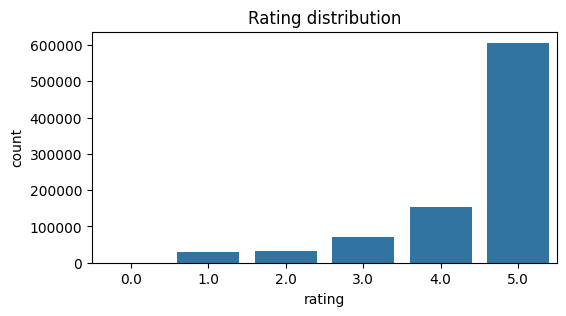

After filtering (user>=3, item>=5): 264,921
Interactions: 264,921
Users: 54,259
Items: 25,862
Sparsity: 99.9811%
Saved to data/clean_dataset.parquet


In [4]:
print(f"Reviews: {len(df_reviews):,}")
print(f"Missing values: {int(df_reviews.isna().sum().sum())}")

n_dup = df_reviews.duplicated(subset=["user_id", "parent_asin"]).sum()
print(f"Duplicate (user, item) pairs: {n_dup:,}")

df_reviews = df_reviews.drop_duplicates(subset=["user_id", "parent_asin"], keep="last")
print(f"After deduplication: {len(df_reviews):,}")

plt.figure(figsize=(6, 3))
sns.countplot(data=df_reviews, x="rating")
plt.title("Rating distribution")
plt.show()

user_counts = df_reviews["user_id"].value_counts()
item_counts = df_reviews["parent_asin"].value_counts()

valid_users = user_counts[user_counts >= MIN_USER_INTERACTIONS].index
valid_items = item_counts[item_counts >= MIN_ITEM_INTERACTIONS].index

df_filtered = df_reviews[
    df_reviews["user_id"].isin(valid_users) &
    df_reviews["parent_asin"].isin(valid_items)
].copy()
print(f"After filtering (user>={MIN_USER_INTERACTIONS}, item>={MIN_ITEM_INTERACTIONS}): {len(df_filtered):,}")

meta_cols = ["parent_asin", "main_category", "price", "store", "categories"]
meta_cols = [c for c in meta_cols if c in df_meta.columns]
df_meta_subset = df_meta[meta_cols].drop_duplicates(subset=["parent_asin"])

df_final = df_filtered.merge(df_meta_subset, on="parent_asin", how="left")

df_final["price"] = pd.to_numeric(df_final["price"], errors="coerce")
df_final["price"] = df_final["price"].fillna(df_final["price"].median())
df_final["store"] = df_final["store"].fillna("Unknown")
df_final["main_category"] = df_final["main_category"].fillna("Books")

num_users = df_final["user_id"].nunique()
num_items = df_final["parent_asin"].nunique()
sparsity = 1.0 - len(df_final) / (num_users * num_items)

print(f"Interactions: {len(df_final):,}")
print(f"Users: {num_users:,}")
print(f"Items: {num_items:,}")
print(f"Sparsity: {sparsity:.4%}")

df_final.to_parquet(DATA_DIR / "clean_dataset.parquet")
print(f"Saved to {DATA_DIR / 'clean_dataset.parquet'}")

## Train / validation / test split

**Разбиение временное:** данные сортируются по `timestamp`, затем делятся на 80% / 10% / 10%. Это соответствует реальной постановке рекомендаций — предсказать будущие взаимодействия по прошлым. Случайное разбиение здесь привело бы к утечке информации о будущем.

**Холодный старт:** После разбиения из `val` и `test` удаляются пользователи и объекты, которых нет в `train`: для них модель не может построить эмбеддинги или соседей, и оценка была бы заведомо нулевой.

In [5]:
df = pd.read_parquet(DATA_DIR / "clean_dataset.parquet")
df = df.sort_values("timestamp").reset_index(drop=True)

n = len(df)
train_end = int(n * 0.8)
val_end = int(n * 0.9)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

# Drop cold-start users and items from val/test
train_users = set(train_df["user_id"])
train_items = set(train_df["parent_asin"])

val_df = val_df[val_df["user_id"].isin(train_users) & val_df["parent_asin"].isin(train_items)]
test_df = test_df[test_df["user_id"].isin(train_users) & test_df["parent_asin"].isin(train_items)]

print(f"Train: {len(train_df):,} rows, {train_df['user_id'].nunique():,} users")
print(f"Val:   {len(val_df):,} rows, {val_df['user_id'].nunique():,} users")
print(f"Test:  {len(test_df):,} rows, {test_df['user_id'].nunique():,} users")

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    part.to_parquet(DATA_DIR / f"{name}.parquet")

print(f"Saved to {DATA_DIR}")

Train: 211,936 rows, 47,929 users
Val:   13,255 rows, 6,727 users
Test:  9,403 rows, 4,993 users
Saved to data


## Evaluation protocol

Метрики считаются при `K = 10` на одних и тех же пользователях `val` (и позже `test`) и одних и тех же множествах релевантных объектов.

**Recall@10** — доля релевантных книг пользователя, попавших в top-10 рекомендаций. Основная метрика: напрямую измеряет, насколько хорошо модель «находит» будущие взаимодействия.

**NDCG@10** — учитывает позицию попадания: чем выше релевантный объект в списке, тем больше вклад. Дополняет Recall, потому что различает модели с одинаковым числом попаданий, но разным порядком.

In [6]:
val_users = val_df["user_id"].unique()

def evaluate_model(recommendations, test_df, k=K):
    recalls, ndcgs = [], []
    test_grouped = test_df.groupby("user_id")["parent_asin"].apply(list).to_dict()
    for user, actual_items in test_grouped.items():
        if user not in recommendations:
            continue
        recs = recommendations[user][:k]
        actual_set = set(actual_items)
        hits = len(set(recs) & actual_set)
        recalls.append(hits / len(actual_set))
        dcg = sum(1.0 / np.log2(i + 2) for i, item in enumerate(recs) if item in actual_set)
        idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(actual_set), k)))
        ndcgs.append(dcg / idcg if idcg > 0 else 0.0)
    return np.mean(recalls), np.mean(ndcgs)

## 1. ItemKNN

Item-based CF на косинусном сходстве. Строится матрица взаимодействий $R$ (значение — рейтинг), столбцы нормируются на L2, сходство объектов:

$$
S = (R D^{-1})^\top (R D^{-1}), \quad D = \mathrm{diag}(\lVert r_i \rVert_2)
$$

В `S` оставляются `k_neighbors = 50` ближайших соседей на объект (диагональ обнулена). Скор для пользователя $u$:

$$
\hat{r}_u = R_u \, S
$$

Рекомендации — top-$K$ по $\hat{r}_u$ среди объектов, которых нет у пользователя в `train` (им присваивается $-\infty$).

In [7]:
from models.item_cf import ItemKNN

start_time = time.time()
item_knn = ItemKNN(k_neighbors=50, verbose=True)
item_knn.fit(train_df)

val_recs_knn = item_knn.recommend(
    val_users, candidates=None, k=K, exclude_seen=True, train_df=train_df
)
elapsed = time.time() - start_time

recall_knn, ndcg_knn = evaluate_model(val_recs_knn, val_df, k=K)
print(f"ItemKNN | Recall@{K}: {recall_knn:.4f} | NDCG@{K}: {ndcg_knn:.4f} | {elapsed:.1f}s")

[ItemKNN] users=47929, items=23536, nnz_R=211936, nnz_S=960776
ItemKNN | Recall@10: 0.0140 | NDCG@10: 0.0101 | 8.4s


## 2. ALS (implicit)

Матричная факторизация $R \approx P Q^\top$ с поочерёдным решением задачи наименьших квадратов по $P$ при фиксированном $Q$ и наоборот.

**Неявная обратная связь.** Каждый отзыв — положительное взаимодействие ($p_{ui} = 1$), уверенность растёт с рейтингом: $c_{ui} = \alpha \, r_{ui}$. Функция потерь:

$$
\mathcal{L} = \sum_{u,i} c_{ui} \, (p_{ui} - p_u^\top q_i)^2 + \lambda\!\left(\lVert P \rVert_F^2 + \lVert Q \rVert_F^2\right)
$$

$$
p_u = (Q^\top C_u Q + \lambda I)^{-1} Q^\top C_u \mathbf{1}
$$

где $C_u = \mathrm{diag}(c_{ui})$.

**Рекомендации.** Скор $\hat{r}_{ui} = p_u^\top q_i$, top-$K$ среди объектов вне `train` пользователя.

**Гиперпараметры.** $d = 32$, $\lambda = 0.1$, $\alpha = 40$, 15 итераций.

In [8]:
from models.als import ALS

start_time = time.time()
als_model = ALS(n_factors=32, n_iter=15, reg=0.1, implicit=True, alpha=40.0, verbose=True)
als_model.fit(train_df)

val_recs_als = als_model.recommend(
    val_users, candidates=None, k=K, exclude_seen=True, train_df=train_df
)
elapsed = time.time() - start_time

recall_als, ndcg_als = evaluate_model(val_recs_als, val_df, k=K)
print(f"ALS (implicit) | Recall@{K}: {recall_als:.4f} | NDCG@{K}: {ndcg_als:.4f} | {elapsed:.1f}s")

[ALS] iter 1/15
[ALS] iter 2/15
[ALS] iter 3/15
[ALS] iter 4/15
[ALS] iter 5/15
[ALS] iter 6/15
[ALS] iter 7/15
[ALS] iter 8/15
[ALS] iter 9/15
[ALS] iter 10/15
[ALS] iter 11/15
[ALS] iter 12/15
[ALS] iter 13/15
[ALS] iter 14/15
[ALS] iter 15/15
ALS (implicit) | Recall@10: 0.0197 | NDCG@10: 0.0125 | 78.7s


## 3. SLIM

Обучается разреженная матрица весов объектов $W \in \mathbb{R}^{|I| \times |I|}$ такая, что взаимодействия восстанавливаются как $X \approx XW$, где $X$ — бинарная матрица user × item.

$$
\min_{W \geq 0,\ \mathrm{diag}(W)=0} \; \lVert X - XW \rVert_F^2 + \lambda_2 \lVert W \rVert_F^2 + \lambda_1 \lVert W \rVert_1
$$

Ограничение $\mathrm{diag}(W) = 0$ запрещает объекту предсказывать самого себя, неотрицательность даёт интерпретируемые «положительные» веса.

**Оптимизация.** Столбцы $W$ решаются независимо проксимальным градиентным спуском: шаг по градиенту, затем soft-thresholding для L1, затем проекция на $w \geq 0$ и обнуление $w_j$.

**Рекомендации.** Скор $\hat{y}_u = x_u W$ — top-$K$ среди объектов вне `train` пользователя.

**Гиперпараметры.** $\lambda_1 = \lambda_2 = 0.1$, $10$ итераций, learning rate $0.01$.

In [9]:
from models.slim import SLIM

start_time = time.time()
slim_model = SLIM(l1_reg=0.1, l2_reg=0.1, max_iter=10, learning_rate=0.01)
slim_model.fit(train_df)

val_recs_slim = slim_model.recommend(
    val_users, k=K, exclude_seen=True, train_df=train_df
)
elapsed = time.time() - start_time

recall_slim, ndcg_slim = evaluate_model(val_recs_slim, val_df, k=K)
print(f"SLIM | Recall@{K}: {recall_slim:.4f} | NDCG@{K}: {ndcg_slim:.4f} | {elapsed:.1f}s")

Training SLIM...
Processed 5000 / 23536 items
Processed 10000 / 23536 items
Processed 15000 / 23536 items
Processed 20000 / 23536 items
SLIM training finished.
SLIM | Recall@10: 0.0155 | NDCG@10: 0.0115 | 469.4s


## 4. FM (Factorization Machine)

FM моделирует попарные взаимодействия one-hot признаков через низкоранговые эмбеддинги:

$$
\hat{y}(x) = w_0 + \sum_{i} w_i x_i + \sum_{i < j} \langle v_i, v_j \rangle \, x_i x_j
$$

Взаимодействия считаются за $O(nk)$:

$$
\sum_{i<j} \langle v_i, v_j \rangle x_i x_j = \tfrac{1}{2} \sum_{f=1}^{k} \Big[ \big( \textstyle\sum_i v_{i,f} x_i \big)^2 - \sum_i v_{i,f}^2 x_i^2 \Big]
$$

**Признаки** (5 полей на взаимодействие, all one-hot):
- `user_id` — идентификатор пользователя;
- `parent_asin` — идентификатор книги;
- `store` — издательство / магазин (метаданные книги);
- `main_category` — основная категория книги;
- `price_bin` — цена, разбитая на 4 квантильных бакета.

**Обучение.** Для каждого положительного взаимодействия сэмплируется `neg_samples = 3` случайных книги, которых нет в истории пользователя. Функция потерь — бинарная кросс-энтропия на логитах:

$$
\mathcal{L} = -\frac{1}{N} \sum_{i=1}^{N} \big[ y_i \log \sigma(\hat{y}_i) + (1 - y_i) \log (1 - \sigma(\hat{y}_i)) \big]
$$

**Инференс.** Для пользователя $u$ и книги $i$ со всеми метаданными:

$$
\hat{y}_{ui} = w_0 + w_u + \sum_{m} w_m + \tfrac{1}{2}\Big[ \big( v_u + \sum_{m} v_m \big)^2 - v_u^2 - \sum_{m} v_m^2 \Big]
$$

где $m$ — метапризнаки книги. Top-$K$ по $\hat{y}_{ui}$ среди объектов вне `train` пользователя.

**Гиперпараметры.** $k = 32$, $\mathrm{lr} = 0.01$, $5$ эпох, batch size $8192$, Adam с `weight_decay = 1e-5`.

In [10]:
from models.fm import FMWrapper

train_df_fm = train_df.copy()
train_df_fm["price"] = train_df_fm["price"].fillna(train_df_fm["price"].median())
train_df_fm["store"] = train_df_fm["store"].fillna("Unknown")
train_df_fm["main_category"] = train_df_fm["main_category"].fillna("Unknown")

start_time = time.time()
fm_model = FMWrapper(k=32, lr=0.01, epochs=5, batch_size=8192)
fm_model.fit(train_df_fm, neg_samples=3, seed=RANDOM_SEED)

val_recs_fm = fm_model.recommend(val_users, train_df_fm, k=K)
elapsed = time.time() - start_time

recall_fm, ndcg_fm = evaluate_model(val_recs_fm, val_df, k=K)
print(f"FM | Recall@{K}: {recall_fm:.4f} | NDCG@{K}: {ndcg_fm:.4f} | {elapsed:.1f}s")

Training FM on 355691 examples
Epoch 1/5, Loss: 0.6289
Epoch 2/5, Loss: 0.5433
Epoch 3/5, Loss: 0.5283
Epoch 4/5, Loss: 0.5206
Epoch 5/5, Loss: 0.5183
FM | Recall@10: 0.0208 | NDCG@10: 0.0127 | 38.5s


## 5. Time-aware iALS

iALS с кастомным целевым сигналом: вместо бинарного индикатора взаимодействия используется recency-weighted normalized rating.

**Целевой сигнал.**

$$
\text{decay}(t_{ui}) = 0.2 + 0.8 \cdot 0.5^{\,\Delta_{ui} / T_{1/2}}, \qquad p_{ui} = \text{decay}(t_{ui}) \cdot \frac{r_{ui}}{5}
$$

где $\Delta_{ui}$ — давность отзыва в днях относительно последнего отзыва в `train`, $T_{1/2} = 365$ дней, $r_{ui}$ — оценка.

**Loss** — как в iALS, с уверенностью $c_{ui} = \alpha \, r_{ui}$:

$$
\mathcal{L} = \sum_{u,i} c_{ui} \, (p_{ui} - p_u^\top q_i)^2 + \lambda\!\left(\lVert P \rVert_F^2 + \lVert Q \rVert_F^2\right)
$$

**Обоснование.** Свежие отзывы информативнее старых для предсказания следующей книги; базовая ценность $0.2$ не даёт обнулить давнюю историю. Нормировка $r_{ui}/5$ приводит таргет к $[0, 1]$.

**Сравнение с iALS.** Тот же loss, та же уверенность, те же гиперпараметры ($d = 32$, $\lambda = 0.1$, $\alpha = 40$) и тот же алгоритм поочерёдных наименьших квадратов. Отличие — только целевой сигнал $p_{ui}$: бинарный индикатор → recency-weighted rating. Это разработка нового таргета, а не подбор гиперпараметров и не пересчёт confidence.

In [11]:
from models.time_ials import TimeIALS

start_time = time.time()
time_ials = TimeIALS(
    n_factors=32, n_iter=15, reg=0.1, alpha=40.0,
    half_life_days=365.0, random_state=RANDOM_SEED, verbose=True,
)
time_ials.fit(train_df)

val_recs_time = time_ials.recommend(
    val_users, k=K, exclude_seen=True, train_df=train_df
)
elapsed = time.time() - start_time

recall_time, ndcg_time = evaluate_model(val_recs_time, val_df, K)
print(f"TimeIALS | Recall@{K}: {recall_time:.4f} | NDCG@{K}: {ndcg_time:.4f} | {elapsed:.1f}s")

[TimeIALS] iter 1/15
[TimeIALS] iter 2/15
[TimeIALS] iter 3/15
[TimeIALS] iter 4/15
[TimeIALS] iter 5/15
[TimeIALS] iter 6/15
[TimeIALS] iter 7/15
[TimeIALS] iter 8/15
[TimeIALS] iter 9/15
[TimeIALS] iter 10/15
[TimeIALS] iter 11/15
[TimeIALS] iter 12/15
[TimeIALS] iter 13/15
[TimeIALS] iter 14/15
[TimeIALS] iter 15/15
TimeIALS | Recall@10: 0.0294 | NDCG@10: 0.0199 | 78.2s


In [12]:
test_users = test_df["user_id"].unique()

test_recs_knn  = item_knn.recommend(test_users, candidates=None, k=K, exclude_seen=True, train_df=train_df)
test_recs_als  = als_model.recommend(test_users, candidates=None, k=K, exclude_seen=True, train_df=train_df)
test_recs_slim = slim_model.recommend(test_users, k=K, exclude_seen=True, train_df=train_df)
test_recs_fm   = fm_model.recommend(test_users, train_df_fm, k=K)
test_recs_time = time_ials.recommend(test_users, k=K, exclude_seen=True, train_df=train_df)

test_metrics = {}
for name, recs in [
    ("ItemKNN",  test_recs_knn),
    ("ALS",      test_recs_als),
    ("SLIM",     test_recs_slim),
    ("FM",       test_recs_fm),
    ("TimeIALS", test_recs_time),
]:
    r, n = evaluate_model(recs, test_df, k=K)
    test_metrics[name] = {"recall": r, "ndcg": n}
    print(f"{name:10s} | Recall@{K}: {r:.4f} | NDCG@{K}: {n:.4f}")

ItemKNN    | Recall@10: 0.0079 | NDCG@10: 0.0052
ALS        | Recall@10: 0.0210 | NDCG@10: 0.0148
SLIM       | Recall@10: 0.0116 | NDCG@10: 0.0086
FM         | Recall@10: 0.0344 | NDCG@10: 0.0255
TimeIALS   | Recall@10: 0.0197 | NDCG@10: 0.0123


In [14]:
val_metrics = {
    "ItemKNN":  (recall_knn,  ndcg_knn),
    "ALS":      (recall_als,  ndcg_als),
    "SLIM":     (recall_slim, ndcg_slim),
    "FM":       (recall_fm,   ndcg_fm),
    "TimeIALS": (recall_time, ndcg_time),
}

summary = pd.DataFrame([
    {
        "Model": name,
        "Recall@10 (val)":  val_metrics[name][0],
        "NDCG@10 (val)":    val_metrics[name][1],
        "Recall@10 (test)": test_metrics[name]["recall"],
        "NDCG@10 (test)":   test_metrics[name]["ndcg"],
    }
    for name in val_metrics
]).round(4)

summary

,Model,Recall@10 (val),NDCG@10 (val),Recall@10 (test),NDCG@10 (test)
0,ItemKNN,0.0140,0.0101,0.0079,0.0052
1,ALS,0.0197,0.0125,0.0210,0.0148
2,SLIM,0.0155,0.0115,0.0116,0.0086
3,FM,0.0208,0.0127,0.0344,0.0255
4,TimeIALS,0.0294,0.0199,0.0197,0.0123


## Summary and conclusions

### Results

| Model | Recall@10 (val) | NDCG@10 (val) | Recall@10 (test) | NDCG@10 (test) |
|---|---|---|---|---|
| ItemKNN | 0.0140 | 0.0101 | 0.0079 | 0.0052 |
| ALS | 0.0197 | 0.0125 | 0.0210 | 0.0148 |
| SLIM | 0.0155 | 0.0115 | 0.0116 | 0.0086 |
| **FM** | 0.0208 | 0.0127 | **0.0344** | **0.0255** |
| TimeIALS | **0.0294** | **0.0199** | 0.0197 | 0.0123 |

### Analysis

Главный результат: на test выиграл FM, а не TimeIALS, который лидировал на validation. Причём FM - единственная модель, которая на test улучшилась относительно val (0.0208 -> 0.0344). Объяснение простое: val по времени примыкает к train, и recency-weighted сигнал TimeIALS хорошо попадает именно туда, но не переносится на более далёкое будущее. Метаданные (`store`, `main_category`, `price_bin`) же дают стабильный сигнал, который не устаревает.

ALS - единственная CF-модель без просадки (0.0197 -> 0.0210). ItemKNN и SLIM заметно просели, что ожидаемо: их скоры опираются на совпадение истории пользователя с текущим моментом, а на длинном горизонте это совпадение слабеет.

### Limitations

- Один split, гиперы не подбирались. Test - однократная проверка, не итог тюнинга.
- TimeIALS с $T_{1/2} = 365$ дней: выигрыш на val даёт rating-weighted таргет, а не recency (при $T_{1/2} = 30$ val падает до 0.0232).